In [1]:
import perf
import pandas as pd

In [2]:
perf.cpuinfo()

,cpu,core,numa,arch,platform,vendor,model,family,stepping,freq,L1i,L1d,L2,L3
0,0,0,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
1,1,4,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
2,2,8,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
3,3,12,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
4,4,16,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
5,5,20,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,32Kb,48Kb,1280Kb,24576Kb
6,6,28,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
7,7,29,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
8,8,30,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb
9,9,31,0,x86_64,Linux-6.2.0-39-generic-x86_64-with-glibc2.37,12th Gen Intel(R) Core(TM) i7-12650H,154,6,3,2688000000,64Kb,32Kb,2048Kb,24576Kb


In [3]:
perf.tune()

,setting,path,current,target,status
0,aslr,/proc/sys/kernel/randomize_va_space,on,on,unchanged
1,governor,/sys/devices/system/cpu/cpu*/cpufreq/scaling_g...,powersave,powersave,unchanged
2,energy_performance_preference,/sys/devices/system/cpu/cpu*/cpufreq/energy_pe...,balance_performance,balance_performance,unchanged
3,cpu_frequency,/sys/devices/system/cpu/cpu*/cpufreq/scaling_{...,400MHz..4.6GHz;400MHz..4.7GHz;400MHz..3.5GHz,range,unchanged
4,turbo,/sys/devices/system/cpu/intel_pstate/no_turbo,on,on,unchanged
5,turbo_msr,/dev/cpu/*/msr,,on,unavailable
6,boost,/sys/devices/system/cpu/cpufreq/boost,,on,unavailable
7,smt,/sys/devices/system/cpu/smt/control,on,on,unchanged
8,nmi_watchdog,/proc/sys/kernel/nmi_watchdog,on,on,unchanged
9,watchdog,/proc/sys/kernel/watchdog,on,on,unchanged


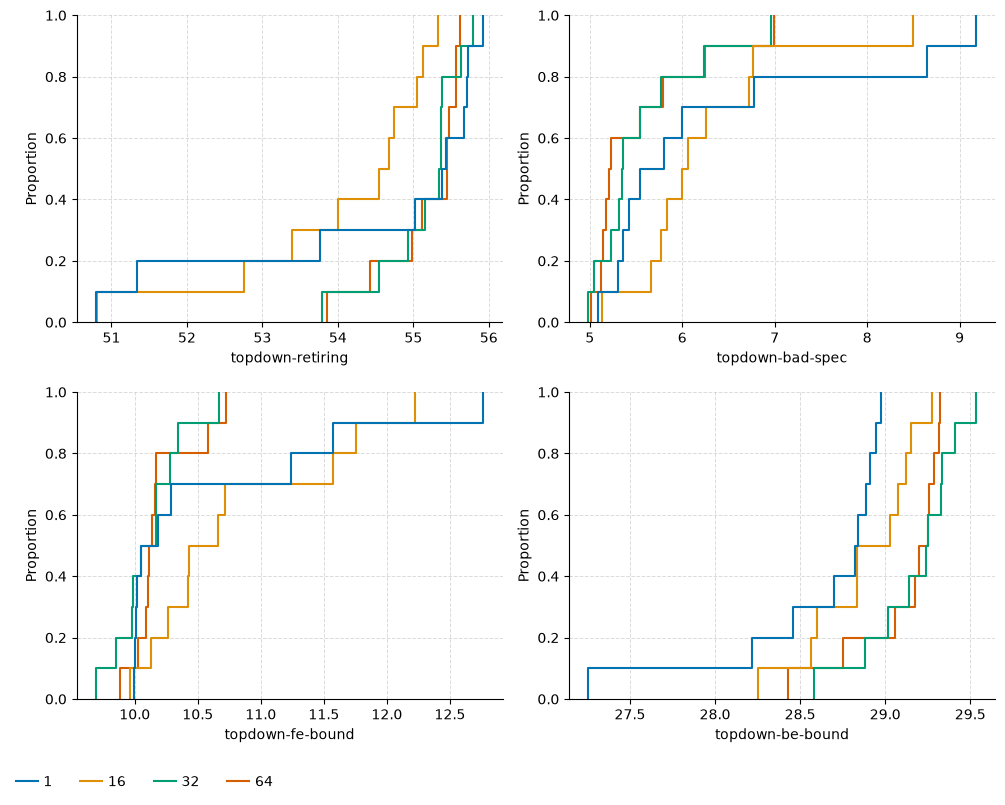

[]

In [4]:
REGS = ["rax", "rdx", "rsi", "rdi", "r11"]
BODY = "\n".join(f"add {REGS[i % len(REGS)]}, {i + 1}" for i in range(128))
CODE = f"mov ecx, 100\n.L:\n{BODY}\ndec ecx\njnz .L\nret"
CONFIG = {
    "code": [{"align": 1}, {"align": 16}, {"align": 32}, {"align": 64}],
    "icache": "hot",
    "dcache": "hot",
    "dtlb": "hot",
    "itlb": "hot",
    "branch": "predictable",
    "samples": 60,
}
top = perf.benchmark(
    asm=CODE,
    mode=["latency"],
    event=["topdown*"],
    config=CONFIG,
)
perf.plot(top, "ecdf", event=[c for c in top.columns if c.startswith("topdown-")], groupby="config.code.align")

In [5]:
icache = perf.benchmark(
    asm=CODE,
    mode=["latency"],
    event=["cycles", "instructions"],
    config=CONFIG,
)
summary = icache.groupby("config.code.align")[["cycles", "instructions"]].median()
summary["ipc"] = summary["instructions"] / summary["cycles"]
summary.round(2)

,cycles,instructions,ipc
config.code.align,,,
1,2253.0,13000.0,5.77
16,2256.0,13000.0,5.76
32,2184.0,13000.0,5.95
64,2187.0,13000.0,5.94


In [6]:
layout = perf.analyze(asm=CODE, event=["index", "address", "size", "assembly"])
layout["line"] = layout["address"] // 64
layout["offset"] = layout["address"] % 64
layout[["address", "line", "offset", "size", "assembly"]].head(24)

,address,line,offset,size,assembly
0,16777216,262144,0,5,"mov ecx, 0x64"
1,16777221,262144,5,4,"add rax, 1"
2,16777225,262144,9,4,"add rdx, 2"
3,16777229,262144,13,4,"add rsi, 3"
4,16777233,262144,17,4,"add rdi, 4"
5,16777237,262144,21,4,"add r11, 5"
6,16777241,262144,25,4,"add rax, 6"
7,16777245,262144,29,4,"add rdx, 7"
8,16777249,262144,33,4,"add rsi, 8"
9,16777253,262144,37,4,"add rdi, 9"


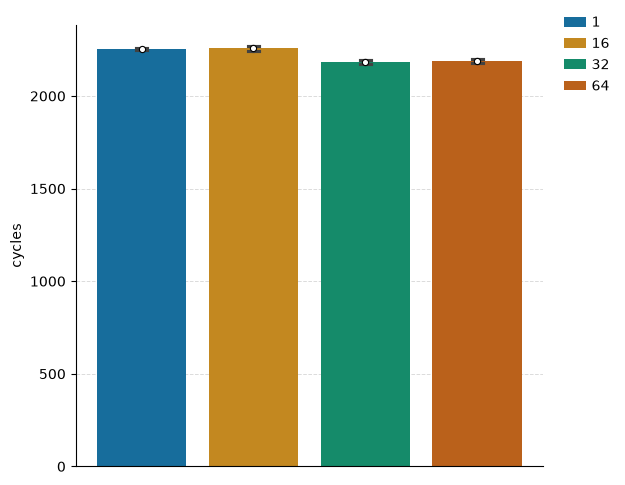

[]

In [7]:
perf.plot(icache, "bar", event="cycles", groupby="config.code.align")